In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [4]:
# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Data types
print(df.dtypes)

# Dataset information
df.info()

Shape: (891, 15)
Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-nu

In [5]:
numerical = df.select_dtypes(include=np.number).columns

categorical = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical)

print("\nCategorical Columns:")
print(categorical)

Numerical Columns:
Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')

Categorical Columns:
Index(['sex', 'embarked', 'class', 'who', 'deck', 'embark_town', 'alive'], dtype='object')


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include='object')

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [8]:
# Missing values in each column
print(df.isnull().sum())

# Percentage of missing values
missing_percentage = (df.isnull().mean() * 100)

print(missing_percentage)

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [9]:
clean_df = df.copy()

In [10]:
# Fill Age with median
clean_df['age'] = clean_df['age'].fillna(
    clean_df['age'].median()
)

# Fill Embarked with mode
clean_df['embarked'] = clean_df['embarked'].fillna(
    clean_df['embarked'].mode()[0]
)

# Fill Fare with median
clean_df['fare'] = clean_df['fare'].fillna(
    clean_df['fare'].median()
)

# Drop Cabin because it has too many missing values
clean_df = clean_df.drop(columns=['deck'])

In [11]:
print(clean_df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [12]:
# Count duplicate rows
print("Duplicates:", clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

print("Duplicates after cleaning:",
      clean_df.duplicated().sum())

Duplicates: 116
Duplicates after cleaning: 0


In [13]:
print(clean_df.describe())

print(clean_df['sex'].value_counts())

print(clean_df['survived'].value_counts())

         survived      pclass         age       sibsp       parch        fare
count  775.000000  775.000000  775.000000  775.000000  775.000000  775.000000
mean     0.412903    2.246452   29.581187    0.529032    0.420645   34.878403
std      0.492674    0.853574   13.766359    0.990326    0.840565   52.408474
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    1.000000   21.000000    0.000000    0.000000    8.050000
50%      0.000000    3.000000   28.000000    0.000000    0.000000   15.900000
75%      1.000000    3.000000   36.000000    1.000000    1.000000   34.197900
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200
sex
male      483
female    292
Name: count, dtype: int64
survived
0    455
1    320
Name: count, dtype: int64


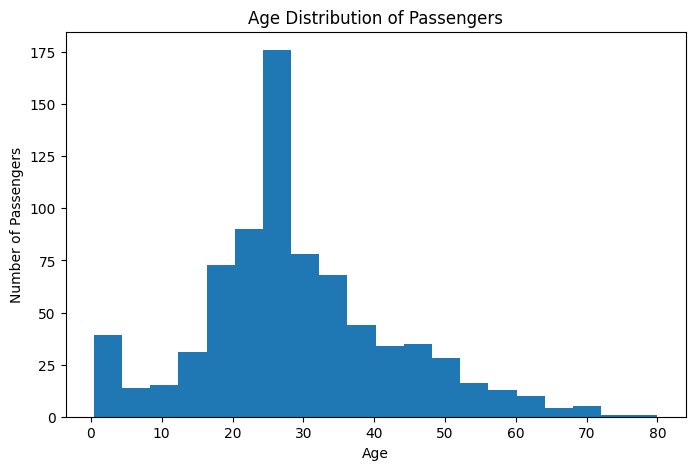

In [14]:
plt.figure(figsize=(8,5))

plt.hist(clean_df['age'], bins=20)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

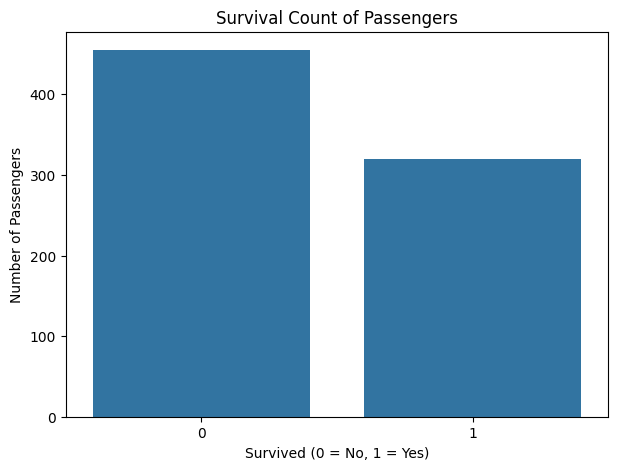

In [15]:
plt.figure(figsize=(7,5))

sns.countplot(data=clean_df, x='survived')

plt.title("Survival Count of Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [16]:
# One-hot encoding
encoded_df = pd.get_dummies(
    clean_df,
    columns=['sex', 'embarked', 'pclass'],
    dtype=int
)

print(encoded_df.head())

   survived   age  sibsp  parch     fare  class    who  adult_male  \
0         0  22.0      1      0   7.2500  Third    man        True   
1         1  38.0      1      0  71.2833  First  woman       False   
2         1  26.0      0      0   7.9250  Third  woman       False   
3         1  35.0      1      0  53.1000  First  woman       False   
4         0  35.0      0      0   8.0500  Third    man        True   

   embark_town alive  alone  sex_female  sex_male  embarked_C  embarked_Q  \
0  Southampton    no  False           0         1           0           0   
1    Cherbourg   yes  False           1         0           1           0   
2  Southampton   yes   True           1         0           0           0   
3  Southampton   yes  False           1         0           0           0   
4  Southampton    no   True           0         1           0           0   

   embarked_S  pclass_1  pclass_2  pclass_3  
0           1         0         0         1  
1           0         1 

In [17]:
scaler = StandardScaler()

columns_to_scale = ['age', 'fare', 'sibsp', 'parch']

encoded_df[columns_to_scale] = scaler.fit_transform(
    encoded_df[columns_to_scale]
)

print(encoded_df.head())

   survived       age     sibsp     parch      fare  class    who  adult_male  \
0         0 -0.551060  0.475876 -0.500754 -0.527515  Third    man        True   
1         1  0.611945  0.475876 -0.500754  0.695086  First  woman       False   
2         1 -0.260308 -0.534545 -0.500754 -0.514627  Third  woman       False   
3         1  0.393881  0.475876 -0.500754  0.347909  First  woman       False   
4         0  0.393881 -0.534545 -0.500754 -0.512240  Third    man        True   

   embark_town alive  alone  sex_female  sex_male  embarked_C  embarked_Q  \
0  Southampton    no  False           0         1           0           0   
1    Cherbourg   yes  False           1         0           1           0   
2  Southampton   yes   True           1         0           0           0   
3  Southampton   yes  False           1         0           0           0   
4  Southampton    no   True           0         1           0           0   

   embarked_S  pclass_1  pclass_2  pclass_3  
0   

In [18]:
# Check missing values
print("Missing values:")
print(encoded_df.isnull().sum().sum())

# Check duplicates
print("Duplicate rows:",
      encoded_df.duplicated().sum())

# Save final dataset
encoded_df.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("Dataset saved successfully!")

Missing values:
2
Duplicate rows: 0
Dataset saved successfully!


In [19]:
from google.colab import files

files.download('Titanic_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>